# Business impact (#41)

Translate Model C's ATT into incremental revenue, then look at profit under a few assumed margins and costs.
All figures are estimates; margins and costs are illustrative, not Estée Lauder data.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent

In [2]:
specs = pd.read_csv(ROOT / "results/m5_three_specifications_hc3.csv")
c = specs[specs["model"] == "C_FE_anticipation_marketing"].iloc[0]
att = {"estimate": c["att_usd_per_session"], "ci_low": c["ci_low"], "ci_high": c["ci_high"]}

df = pd.read_csv(ROOT / "data/market_week_data.csv")
us = df[df["market"] == "United States"]
sessions_pre = us.loc[us["post_launch"] == 0, "sessions"].mean()
sessions_post = us.loc[us["post_launch"] == 1, "sessions"].mean()

att, sessions_pre, sessions_post

({'estimate': np.float64(0.209325694520827),
  'ci_low': np.float64(0.1439891574946735),
  'ci_high': np.float64(0.2746622315469806)},
 np.float64(422638.93846153846),
 np.float64(448050.71794871794))

## Incremental revenue

ATT × sessions/week, using pre-launch U.S. traffic (post-launch traffic as a sensitivity check). Assumes the lift and traffic hold for 52 weeks.

In [3]:
revenue = pd.DataFrame({
    "weekly_pre": {k: v * sessions_pre for k, v in att.items()},
    "annual_pre": {k: v * sessions_pre * 52 for k, v in att.items()},
    "annual_post": {k: v * sessions_post * 52 for k, v in att.items()},
})
revenue.to_csv(ROOT / "results/m6_incremental_revenue.csv")
revenue.round(0)

,weekly_pre,annual_pre,annual_post
estimate,88469.0,4600398.0,4877003.0
ci_low,60855.0,3164482.0,3354751.0
ci_high,116083.0,6036314.0,6399256.0


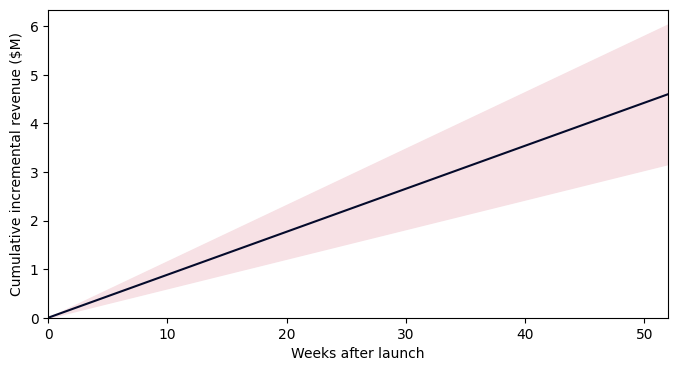

In [4]:
weeks = range(53)
cumulative = pd.DataFrame({k: [v * sessions_pre * w for w in weeks] for k, v in att.items()}, index=weeks)
cumulative.index.name = "week"
cumulative.to_csv(ROOT / "results/m6_cumulative_incremental_revenue.csv")

ax = (cumulative["estimate"] / 1e6).plot(color="#040A2B", figsize=(8, 4))
ax.fill_between(cumulative.index, cumulative["ci_low"] / 1e6, cumulative["ci_high"] / 1e6, color="#F7E1E5")
ax.set(xlabel="Weeks after launch", ylabel="Cumulative incremental revenue ($M)", xlim=(0, 52), ylim=(0, None))
plt.savefig(ROOT / "figures/m6_cumulative_incremental_revenue.png", dpi=200, bbox_inches="tight")

## Revenue is not profit

profit = annual revenue × contribution margin − feature cost; ROI = profit / cost.
Base case is the CA's example: 50% margin, $1M cost.

In [5]:
annual = revenue["annual_pre"]
rows = []
for margin in [0.3, 0.5, 0.7]:
    for cost in [0.5e6, 1e6, 2e6]:
        for bound in annual.index:
            profit = annual[bound] * margin - cost
            rows.append({"margin": margin, "cost": cost, "bound": bound, "profit": profit, "roi": profit / cost})
scenarios = pd.DataFrame(rows)
scenarios.to_csv(ROOT / "results/m6_profit_scenarios.csv", index=False)

scenarios[(scenarios["margin"] == 0.5) & (scenarios["cost"] == 1e6)].round(2)

,margin,cost,bound,profit,roi
12,0.5,1000000.0,estimate,1300198.92,1.30
13,0.5,1000000.0,ci_low,582241.04,0.58
14,0.5,1000000.0,ci_high,2018156.80,2.02


In [6]:
point = scenarios[scenarios["bound"] == "estimate"]
(point.pivot(index="margin", columns="cost", values="profit") / 1e6).round(2)

cost,500000.0,1000000.0,2000000.0
margin,,,
0.3,0.88,0.38,-0.62
0.5,1.80,1.30,0.30
0.7,2.72,2.22,1.22


In [7]:
# margin needed to break even at each cost
pd.DataFrame({"estimate": [cost / annual["estimate"] for cost in [0.5e6, 1e6, 2e6]],
              "ci_low": [cost / annual["ci_low"] for cost in [0.5e6, 1e6, 2e6]]},
             index=[0.5e6, 1e6, 2e6]).round(3)

,estimate,ci_low
500000.0,0.109,0.158
1000000.0,0.217,0.316
2000000.0,0.435,0.632
